___
# <font color= #bbc28d> **Fine-tuning de EfficientNet-B0 y prueba con fotos externas** </font>
#### <font color= #7aa8a7> `Proyecto final · Testing`</font>
- <Strong> Diana Valdivia </Strong> · ITESO

___

Finalmente, entrenaremos el segundo tipo de modelo: una **red preentrenada en ImageNet (EfficientNet-B0)** adaptada a las 4 clases de maíz.

**Qué se hace:**
1. Se entrenan **tres versiones** de EfficientNet-B0 con distintos hiperparámetros.
2. Se comparan en test con la CNN y el Random Forest.
3. Se prueban con **20 fotos externas** (5 por clase, tomadas de internet), que son más parecidas a lo que verá la API en uso real.
4. Se usa **Grad-CAM** para ver en qué parte de la hoja se fija el modelo.

Se usan los mismos datos, split y recortes limpios que en la CNN.

In [ ]:
# Liberías
from google.colab import drive
drive.mount("/content/drive")

import random, subprocess, time, json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import torch, torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms as T, models
from sklearn.metrics import f1_score, recall_score, confusion_matrix

WORK = Path("/content/maize_work")
IMG_DIR = WORK / "raw_segmented"
OUT = Path("/content/drive/MyDrive/maize_out") # Carpeta para guardar pesos
OUT.mkdir(parents=True, exist_ok=True)

PATCH = 96 # tamaño de recorte del índice
IMG_SIZE = 224  # entrada de la red preentrenada
EVAL_K = 8  # recortes por imagen al evaluar
BATCH = 64  
SEED = 42
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
print("dispositivo:", DEVICE, "| torch", torch.__version__)
assert DEVICE == "cuda", "CPU"

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
dispositivo: cuda | torch 2.14.1+cu130


# **<font color= #7aa8a7> Datos </font>**
Se carga el mismo `split_v1.csv` y `patch_index_v1.csv`; el split no se vuelve a calcular.

In [ ]:
# Cargar los splits orevios
from google.colab import files

ZIP = Path("/content/maize_data.zip")
if not IMG_DIR.exists():
    if not ZIP.exists():
        up = files.upload()
        ZIP = Path("/content") / list(up.keys())[0]
    subprocess.run(["unzip", "-q", "-o", str(ZIP), "-d", str(WORK)], check=True)
print(sorted(p.name for p in WORK.iterdir()))          # ['patch_index_v1.csv', 'raw_segmented', 'split_v1.csv']

meta = pd.read_csv(WORK / "split_v1.csv")
idx = pd.read_csv(WORK / "patch_index_v1.csv")
meta["path"] = [str(IMG_DIR / l / k.split("/")[-1]) for l, k in zip(meta["label"], meta["seg_key"])]

CLASSES = sorted(meta["label"].unique())
CLASS_TO_ID = {c: i for i, c in enumerate(CLASSES)}

boxes = {k: g[["y", "x"]].to_numpy() for k, g in idx.groupby("seg_key")}
meta["n_patch"] = meta["seg_key"].map(lambda k: len(boxes.get(k, [])))

assert (idx["size"] == PATCH).all(), "El índice debe ser de 96 px"
assert all(Path(p).exists() for p in meta["path"]), "Faltan imágenes locales"
assert (meta.groupby("group")["split"].nunique() == 1).all(), "Hay grupos en más de un split"

usable = meta[meta["n_patch"] > 0].reset_index(drop=True)
train_df = usable[usable["split"] == "train"].reset_index(drop=True)
val_df = usable[usable["split"] == "val"].reset_index(drop=True)
test_df = usable[usable["split"] == "test"].reset_index(drop=True)
print(pd.crosstab(usable["label"], usable["split"])[["train", "val", "test"]])

['patch_index_v1.csv', 'raw_segmented', 'split_v1.csv']
split            train  val  test
label                            
common_rust        820  179   178
gray_leaf_spot     340   74    75
healthy            812  173   173
northern_blight    639  133   133


# **<font color= #7aa8a7> Transformaciones y las tres versiones </font>**
Los aumentos son los mismos de la CNN. Lo que cambia entre versiones es el tamaño de entrada y los hiperparámetros, que se dejan documentados en los comentarios:
- **v1:** 224 px, configuración base.
- **v2:** 160 px y más regularización (*label smoothing* y *weight decay*), para probar si ayudaba a generalizar.
- **v3:** 224 px, sin *label smoothing* y con tasa de aprendizaje mayor en el cuerpo de la red.

In [29]:
MEAN, STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)

class Rot90:
    def __call__(self, img):
        k = random.randint(0, 3)
        return img.rotate(90 * k) if k else img

# V1
# IMG_SIZE = 224
# train_tf = T.Compose([
#     Rot90(), T.RandomHorizontalFlip(), T.RandomVerticalFlip(),
#     T.RandomResizedCrop(IMG_SIZE, scale=(0.6, 1.0), ratio=(1.0, 1.0)),
#     T.ColorJitter(0.25, 0.25, 0.2, 0.02),
#     T.RandomApply([T.GaussianBlur(5, sigma=(0.1, 1.5))], p=0.3),
#     T.ToTensor(), T.Normalize(MEAN, STD),
# ])
# eval_tf = T.Compose([T.Resize(IMG_SIZE), T.ToTensor(), T.Normalize(MEAN, STD)])

# V2
# IMG_SIZE = 160
# train_tf = T.Compose([
#     Rot90(), T.RandomHorizontalFlip(), T.RandomVerticalFlip(),
#     T.RandomResizedCrop(IMG_SIZE, scale=(0.3, 1.0), ratio=(1.0, 1.0)),
#     T.ColorJitter(0.35, 0.35, 0.3, 0.03),
#     T.RandomApply([T.GaussianBlur(5, sigma=(0.1, 2.0))], p=0.4),
#     T.ToTensor(), T.Normalize(MEAN, STD),
# ])
# eval_tf = T.Compose([T.Resize(IMG_SIZE), T.ToTensor(), T.Normalize(MEAN, STD)])

# V3
IMG_SIZE = 224
train_tf = T.Compose([
    Rot90(), T.RandomHorizontalFlip(), T.RandomVerticalFlip(),
    T.RandomResizedCrop(IMG_SIZE, scale=(0.6, 1.0), ratio=(1.0, 1.0)),
    T.ColorJitter(0.25, 0.25, 0.2, 0.02),
    T.RandomApply([T.GaussianBlur(5, sigma=(0.1, 1.5))], p=0.3),
    T.ToTensor(), T.Normalize(MEAN, STD),
])
eval_tf = T.Compose([T.Resize(IMG_SIZE), T.ToTensor(), T.Normalize(MEAN, STD)])

class PatchDataset(Dataset):
    def __init__(self, df, train):
        self.paths = df["path"].tolist()
        self.keys = df["seg_key"].tolist()
        self.labels = [CLASS_TO_ID[l] for l in df["label"]]
        self.train = train
        self.tf = train_tf if train else eval_tf
        if train:
            self.items = [(i, None) for i in range(len(self.paths))]
        else:
            self.items = []
            for i, k in enumerate(self.keys):
                b = boxes[k]
                sel = np.unique(np.linspace(0, len(b) - 1, EVAL_K).round().astype(int))
                self.items += [(i, (int(b[j][0]), int(b[j][1]))) for j in sel]

    def __len__(self):
        return len(self.items)

    def raw(self, n):
        i, box = self.items[n]
        if box is None:
            b = boxes[self.keys[i]]
            j = random.randrange(len(b)); box = (int(b[j][0]), int(b[j][1]))
        y, x = box
        return Image.open(self.paths[i]).convert("RGB").crop((x, y, x + PATCH, y + PATCH))

    def __getitem__(self, n):
        i = self.items[n][0]
        return self.tf(self.raw(n)), self.labels[i], i

In [ ]:
# Cargar los pesos solo con el train por el desbalance de clases
counts = train_df["label"].value_counts().reindex(CLASSES)
weights = torch.tensor((len(train_df) / (len(CLASSES) * counts)).values, dtype=torch.float32)
print("pesos de clase:", {c: round(float(w), 2) for c, w in zip(CLASSES, weights)})
criterion = nn.CrossEntropyLoss(weight=weights.to(DEVICE))

train_ds = PatchDataset(train_df, train=True)
val_ds = PatchDataset(val_df, train=False)
test_ds = PatchDataset(test_df, train=False)
train_dl = DataLoader(train_ds, batch_size=BATCH, shuffle=True, num_workers=2, drop_last=True)
val_dl = DataLoader(val_ds, batch_size=128, shuffle=False, num_workers=2)
test_dl = DataLoader(test_ds, batch_size=128, shuffle=False, num_workers=2)
y_val, y_test = np.array(val_ds.labels), np.array(test_ds.labels)
print(f"train {len(train_ds.paths)} imgs | val {len(val_ds.paths)} imgs | test {len(test_ds.paths)} imgs")

pesos de clase: {'common_rust': 0.8, 'gray_leaf_spot': 1.92, 'healthy': 0.8, 'northern_blight': 1.02}
train 2611 imgs | val 559 imgs | test 559 imgs


Funciones auxiliares que son las mismas de los otros notebooks (promedio de recortes por imagen). `RESULTS` ya trae los resultados de test del Random Forest y las CNN, para compararlos sin volver a entrenarlos.

In [ ]:
# Funciones de evaluación por imágen
@torch.no_grad()
def predict_images(model, ds, dl):
    model.eval()
    probs = np.zeros((len(ds.paths), len(CLASSES))); cnt = np.zeros(len(ds.paths))
    for x, _, i in dl:
        p = torch.softmax(model(x.to(DEVICE)), 1).cpu().numpy()
        for pi, ii in zip(p, i.numpy()):
            probs[ii] += pi; cnt[ii] += 1
    return probs / cnt[:, None]

def metrics(y, probs):
    pred = probs.argmax(1); labs = list(range(len(CLASSES)))
    return dict(acc=(pred == y).mean(), f1=f1_score(y, pred, average="macro"),
                recall=recall_score(y, pred, labels=labs, average=None),
                cm=confusion_matrix(y, pred, labels=labs), pred=pred)

RESULTS = { 
    "RF (test)":        dict(acc=0.903, f1=0.861, recall=[0.949, 0.560, 0.994, 0.917]),
    "CNN base (test)":  dict(acc=0.952, f1=0.936, recall=[0.966, 0.867, 1.000, 0.917]),
    "CNN color (test)": dict(acc=0.966, f1=0.951, recall=[0.994, 0.893, 1.000, 0.925]),
}

def report(name, y, probs):
    m = metrics(y, probs); RESULTS[name] = m
    print(f"== {name}: accuracy {m['acc']:.3f} | macro-F1 {m['f1']:.3f}")
    print("   recall:", {c: round(float(r), 3) for c, r in zip(CLASSES, m["recall"])})
    print(pd.DataFrame(m["cm"], index=CLASSES, columns=CLASSES), "\n")
    return m

# **<font color= #7aa8a7> Red preentrenada </font>**
`build` carga EfficientNet-B0 con los pesos de ImageNet y cambia la última capa por una de **4 salidas**. Lo que la red ya aprendió (bordes, texturas, formas) se reutiliza y solo se adapta a hojas de maíz.

In [ ]:
from torchvision import models

def build(name, n=len(CLASSES)):
    if name == "efficientnet_b0":
        m = models.efficientnet_b0(weights="DEFAULT"); m.classifier[-1] = nn.Linear(m.classifier[-1].in_features, n)
    elif name == "mobilenet_v3_small":
        m = models.mobilenet_v3_small(weights="DEFAULT"); m.classifier[-1] = nn.Linear(m.classifier[-1].in_features, n)
    return m

def head_params(m):
    return (m.fc if hasattr(m, "fc") else m.classifier).parameters()

# **<font color= #7aa8a7> Versión 1 </font>**
El entrenamiento va en **dos fases**:
1. **Solo la cabeza** (3 épocas): la capa nueva parte de valores al azar. Si se entrenara todo desde el inicio, sus gradientes grandes dañarían lo que la red ya sabía.
2. **Toda la red** (12 épocas) con tasa de aprendizaje baja, para ajustar con cuidado.

In [ ]:
# V1
def fit_pre(name, ep_head=3, ep_full=12, lr_head=1e-3, lr_full=1e-4):
    torch.manual_seed(SEED); random.seed(SEED)
    net = build(name).to(DEVICE)
    best, ep_total = -1.0, 0
    for fase, n_ep, lr, full in [("cabeza", ep_head, lr_head, False), ("todo", ep_full, lr_full, True)]:
        for p in net.parameters(): p.requires_grad = full
        for p in head_params(net): p.requires_grad = True
        opt = torch.optim.AdamW([p for p in net.parameters() if p.requires_grad], lr=lr, weight_decay=1e-4)
        sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=n_ep)
        for _ in range(n_ep):
            ep_total += 1; t0 = time.time(); net.train(); tot, n = 0.0, 0
            for x, y, _ in train_dl:
                x, y = x.to(DEVICE), y.to(DEVICE)
                opt.zero_grad(); loss = criterion(net(x), y); loss.backward(); opt.step()
                tot += loss.item() * len(y); n += len(y)
            sched.step()
            m = metrics(y_val, predict_images(net, val_ds, val_dl))
            print(f"[{name}|{fase}] ép {ep_total:02d} | loss {tot/n:.3f} | val acc {m['acc']:.3f} | val F1 {m['f1']:.3f} | {time.time()-t0:.0f}s")
            if m["f1"] > best:
                best = m["f1"]; torch.save(net.state_dict(), OUT / f"{name}.pt")
    net.load_state_dict(torch.load(OUT / f"{name}.pt", map_location=DEVICE))
    return net, best

net_eff, best = fit_pre("efficientnet_b0")
print("mejor val F1:", round(best, 3))

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 116MB/s] 


[efficientnet_b0|cabeza] ép 01 | loss 0.951 | val acc 0.868 | val F1 0.841 | 35s
[efficientnet_b0|cabeza] ép 02 | loss 0.696 | val acc 0.875 | val F1 0.853 | 34s
[efficientnet_b0|cabeza] ép 03 | loss 0.640 | val acc 0.871 | val F1 0.852 | 44s
[efficientnet_b0|todo] ép 04 | loss 0.550 | val acc 0.918 | val F1 0.899 | 39s
[efficientnet_b0|todo] ép 05 | loss 0.428 | val acc 0.946 | val F1 0.930 | 39s
[efficientnet_b0|todo] ép 06 | loss 0.351 | val acc 0.957 | val F1 0.943 | 39s
[efficientnet_b0|todo] ép 07 | loss 0.338 | val acc 0.953 | val F1 0.938 | 38s
[efficientnet_b0|todo] ép 08 | loss 0.309 | val acc 0.973 | val F1 0.963 | 39s
[efficientnet_b0|todo] ép 09 | loss 0.291 | val acc 0.970 | val F1 0.958 | 37s
[efficientnet_b0|todo] ép 10 | loss 0.271 | val acc 0.968 | val F1 0.956 | 39s
[efficientnet_b0|todo] ép 11 | loss 0.262 | val acc 0.973 | val F1 0.962 | 37s
[efficientnet_b0|todo] ép 12 | loss 0.257 | val acc 0.973 | val F1 0.963 | 39s
[efficientnet_b0|todo] ép 13 | loss 0.262 | va

En la fase 1 el F1 de validación se queda en ~0.85, y al descongelar toda la red sube rápido a más de 0.95. El mejor F1 de validación es **0.963**. Cada época tarda ~40 s en la GPU de Colab.

# **<font color= #7aa8a7> Versión 2 </font>**
Se prueba una variante más regularizada: imágenes de 160 px, *label smoothing* de 0.1, tasa del cuerpo de 3e-5 y *weight decay* de 1e-2.

In [34]:
def fit_pre2(name, tag, ep_head=3, ep_full=15, lr_head=1e-3, lr_bb=3e-5, ls=0.1):
    torch.manual_seed(SEED); random.seed(SEED)
    net = build(name).to(DEVICE)
    crit = nn.CrossEntropyLoss(weight=weights.to(DEVICE), label_smoothing=ls)
    head = list(head_params(net)); head_ids = {id(p) for p in head}
    backbone = [p for p in net.parameters() if id(p) not in head_ids]
    best, ep_total = -1.0, 0
    for fase, n_ep, full in [("cabeza", ep_head, False), ("todo", ep_full, True)]:
        for p in backbone: p.requires_grad = full
        groups = [{"params": head, "lr": lr_head}] + ([{"params": backbone, "lr": lr_bb}] if full else [])
        opt = torch.optim.AdamW(groups, weight_decay=1e-2)
        sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=n_ep)
        for _ in range(n_ep):
            ep_total += 1; t0 = time.time(); net.train(); tot, n = 0.0, 0
            for x, y, _ in train_dl:
                x, y = x.to(DEVICE), y.to(DEVICE)
                opt.zero_grad(); loss = crit(net(x), y); loss.backward(); opt.step()
                tot += loss.item() * len(y); n += len(y)
            sched.step()
            m = metrics(y_val, predict_images(net, val_ds, val_dl))
            print(f"[{tag}|{fase}] ép {ep_total:02d} | loss {tot/n:.3f} | val acc {m['acc']:.3f} | val F1 {m['f1']:.3f} | {time.time()-t0:.0f}s")
            if m["f1"] > best:
                best = m["f1"]; torch.save(net.state_dict(), OUT / f"{name}_{tag}.pt")
    net.load_state_dict(torch.load(OUT / f"{name}_{tag}.pt", map_location=DEVICE))
    return net, best

net_v2, best_v2 = fit_pre2("efficientnet_b0", "v2")
print("mejor val F1:", round(best_v2, 3))

[v2|cabeza] ép 01 | loss 1.076 | val acc 0.818 | val F1 0.776 | 24s
[v2|cabeza] ép 02 | loss 0.922 | val acc 0.853 | val F1 0.821 | 21s
[v2|cabeza] ép 03 | loss 0.877 | val acc 0.857 | val F1 0.830 | 24s
[v2|todo] ép 04 | loss 0.879 | val acc 0.903 | val F1 0.881 | 23s
[v2|todo] ép 05 | loss 0.824 | val acc 0.914 | val F1 0.890 | 25s
[v2|todo] ép 06 | loss 0.791 | val acc 0.918 | val F1 0.899 | 24s
[v2|todo] ép 07 | loss 0.786 | val acc 0.914 | val F1 0.889 | 24s
[v2|todo] ép 08 | loss 0.762 | val acc 0.941 | val F1 0.923 | 25s
[v2|todo] ép 09 | loss 0.751 | val acc 0.934 | val F1 0.914 | 23s
[v2|todo] ép 10 | loss 0.758 | val acc 0.950 | val F1 0.934 | 25s
[v2|todo] ép 11 | loss 0.717 | val acc 0.941 | val F1 0.923 | 23s
[v2|todo] ép 12 | loss 0.733 | val acc 0.952 | val F1 0.937 | 24s
[v2|todo] ép 13 | loss 0.728 | val acc 0.946 | val F1 0.929 | 23s
[v2|todo] ép 14 | loss 0.717 | val acc 0.950 | val F1 0.935 | 24s
[v2|todo] ép 15 | loss 0.712 | val acc 0.950 | val F1 0.934 | 23s
[v2|

La versión 2 **no mejoró**: su mejor F1 de validación es **0.941**, por debajo de la v1 (0.963). La regularización extra y la menor resolución le quitaron más de lo que le dieron.

# **<font color= #7aa8a7> Versión 3 </font>**
Se sube la tasa de aprendizaje del cuerpo a 3e-4, se quita el *label smoothing*, se vuelve a 224 px y se entrena un poco más (2 épocas de cabeza y 15 de red completa).

In [ ]:
# backbone con tasa mayor, más épocas, sin label smoothing
net_v3, best_v3 = fit_pre2("efficientnet_b0", "v3", ep_head=2, ep_full=15, lr_head=1e-3, lr_bb=3e-4, ls=0.0)
print("mejor val F1:", round(best_v3, 3))

[v3|cabeza] ép 01 | loss 0.951 | val acc 0.868 | val F1 0.841 | 38s
[v3|cabeza] ép 02 | loss 0.708 | val acc 0.866 | val F1 0.843 | 34s
[v3|todo] ép 03 | loss 0.464 | val acc 0.948 | val F1 0.932 | 43s
[v3|todo] ép 04 | loss 0.378 | val acc 0.962 | val F1 0.950 | 41s
[v3|todo] ép 05 | loss 0.319 | val acc 0.970 | val F1 0.956 | 38s
[v3|todo] ép 06 | loss 0.291 | val acc 0.964 | val F1 0.955 | 39s
[v3|todo] ép 07 | loss 0.273 | val acc 0.964 | val F1 0.952 | 37s
[v3|todo] ép 08 | loss 0.254 | val acc 0.970 | val F1 0.960 | 39s
[v3|todo] ép 09 | loss 0.244 | val acc 0.977 | val F1 0.966 | 39s
[v3|todo] ép 10 | loss 0.207 | val acc 0.977 | val F1 0.968 | 38s
[v3|todo] ép 11 | loss 0.195 | val acc 0.977 | val F1 0.967 | 38s
[v3|todo] ép 12 | loss 0.184 | val acc 0.973 | val F1 0.964 | 37s
[v3|todo] ép 13 | loss 0.190 | val acc 0.971 | val F1 0.961 | 39s
[v3|todo] ép 14 | loss 0.174 | val acc 0.977 | val F1 0.967 | 36s
[v3|todo] ép 15 | loss 0.160 | val acc 0.973 | val F1 0.963 | 38s
[v3|to

La versión 3 llega a un F1 de validación de **0.970**, el mejor de las tres. Como las versiones cambian varias cosas a la vez, **no se puede atribuir la mejora a un solo cambio**.

# **<font color= #7aa8a7> Comparación en test </font>**
Se evalúan las tres versiones en test, cada una con su tamaño de entrada, y se juntan con el Random Forest y las CNN.

In [48]:
VERSIONS = [("EfficientNet-B0 v1", "efficientnet_b0.pt", 224),
            ("EfficientNet-B0 v2", "efficientnet_b0_v2.pt", 160),
            ("EfficientNet-B0 v3", "efficientnet_b0_v3.pt", 224)]

RESULTS.pop("EfficientNet-B0 (test)", None)       # entrada vieja de la primera corrida

for name, f, size in VERSIONS:
    net = build("efficientnet_b0").to(DEVICE)
    net.load_state_dict(torch.load(OUT / f, map_location=DEVICE))
    ds = PatchDataset(test_df, train=False)
    ds.tf = T.Compose([T.Resize(size), T.ToTensor(), T.Normalize(MEAN, STD)])     # tamaño de esta versión
    dl = DataLoader(ds, batch_size=128, shuffle=False, num_workers=2)
    report(f"{name} (test)", y_test, predict_images(net, ds, dl))

rows = {k: dict(accuracy=v["acc"], macro_F1=v["f1"], **{f"recall {c}": r for c, r in zip(CLASSES, v["recall"])})
        for k, v in RESULTS.items() if "test" in k}
print(pd.DataFrame(rows).T.round(3).to_string())

== EfficientNet-B0 v1 (test): accuracy 0.950 | macro-F1 0.937
   recall: {'common_rust': 0.944, 'gray_leaf_spot': 0.907, 'healthy': 1.0, 'northern_blight': 0.917}
                 common_rust  gray_leaf_spot  healthy  northern_blight
common_rust              168               1        0                9
gray_leaf_spot             1              68        1                5
healthy                    0               0      173                0
northern_blight            0              11        0              122 

== EfficientNet-B0 v2 (test): accuracy 0.937 | macro-F1 0.922
   recall: {'common_rust': 0.949, 'gray_leaf_spot': 0.88, 'healthy': 1.0, 'northern_blight': 0.872}
                 common_rust  gray_leaf_spot  healthy  northern_blight
common_rust              169               1        0                8
gray_leaf_spot             0              66        1                8
healthy                    0               0      173                0
northern_blight            4      

| Modelo | Accuracy | macro-F1 |
|---|---|---|
| Random Forest | 0.903 | 0.861 |
| CNN segmented | 0.952 | 0.936 |
| CNN color | 0.966 | 0.951 |
| EfficientNet-B0 v1 | 0.950 | 0.937 |
| EfficientNet-B0 v2 | 0.937 | 0.922 |
| **EfficientNet-B0 v3** | **0.962** | **0.949** |

Todos los modelos con redes neuronales quedan **muy cerca entre sí** (0.92 a 0.95 de macro-F1), con diferencias del orden del ruido para un test de 559 imágenes. Lo que sí es claro es que **todos superan al Random Forest**.

Se elige la **v3** por tener el mejor F1 de validación entre las EfficientNet, y porque, a diferencia de la CNN a color, se entrena con tejido limpio. En todas las versiones el error que más se repite es entre `gray_leaf_spot` y `northern_blight`.

# **<font color= #7aa8a7> Fotos externas </font>**
El test de PlantVillage son fotos de laboratorio o muy similares al conjunto de entrenamiento, así que es optimista. Para tener una idea más realista se suben **20 fotos de internet (5 por clase)**.

In [ ]:
# Cargar zip de fotos externas
from google.colab import files
up = files.upload()
zname = list(up.keys())[0]
subprocess.run(["unzip", "-q", "-o", zname, "-d", "/content"], check=True)
EXT_DIR = Path("/content/external_test")      # si tu zip tiene otra carpeta raíz, ajusta esta ruta
print({c.name: len(list(c.glob("*.*"))) for c in sorted(EXT_DIR.iterdir()) if c.is_dir()})

Saving external_test.zip to external_test.zip
{'common_rust': 5, 'gray_leaf_spot': 5, 'healthy': 5, 'northern_blight': 5}


**Carga de los 5 modelos** (3 EfficientNet y las 2 CNN), cada uno con su tamaño de entrada, para compararlos con las mismas fotos.

In [ ]:
# carga los modelos entrenados (cada uno con su tamaño de entrada).
def eblock(i, o):
    return nn.Sequential(
        nn.Conv2d(i, o, 3, padding=1, bias=False), nn.BatchNorm2d(o), nn.ReLU(inplace=True),
        nn.Conv2d(o, o, 3, padding=1, bias=False), nn.BatchNorm2d(o), nn.ReLU(inplace=True),
        nn.MaxPool2d(2))

class SmallCNN(nn.Module):                     # misma arquitectura que la CNN casera
    def __init__(self, n_classes, p=0.3):
        super().__init__()
        self.features = nn.Sequential(eblock(3, 32), eblock(32, 64), eblock(64, 128), eblock(128, 192))
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(p), nn.Linear(192, n_classes))
    def forward(self, x):
        return self.head(self.features(x))


MODELS = {}
# redes preentrenadas: (archivo, tamaño de entrada)
for name, f, size in [("EfficientNet-B0", "efficientnet_b0.pt", 224),
                      ("EfficientNet-B0 v2", "efficientnet_b0_v2.pt", 160),
                      ("EfficientNet-B0 v3", "efficientnet_b0_v3.pt", 224)]:
    if (OUT / f).exists():
        net = build("efficientnet_b0").to(DEVICE)
        net.load_state_dict(torch.load(OUT / f, map_location=DEVICE)); MODELS[name] = (net.eval(), size)
    else:
        print("No encontré", f)
    if (OUT / f).exists():
        net = build("efficientnet_b0").to(DEVICE)
        net.load_state_dict(torch.load(OUT / f, map_location=DEVICE)); MODELS[name] = (net.eval(), size)
    else:
        print("No encontré", f)

# CNN caseras: (archivo, tamaño de entrada)
for name, f in [("CNN segmented", "cnn_base.pt"), ("CNN color", "cnn_color.pt")]:
    if (OUT / f).exists():
        net = SmallCNN(len(CLASSES)).to(DEVICE)
        net.load_state_dict(torch.load(OUT / f, map_location=DEVICE)); MODELS[name] = (net.eval(), 96)
    else:
        print("No encontré", f)
print("Modelos cargados:", list(MODELS))

Modelos cargados: ['EfficientNet-B0', 'EfficientNet-B0 v2', 'EfficientNet-B0 v3', 'CNN segmented', 'CNN color']


# **<font color= #7aa8a7> Prueba con las fotos externas </font>**
Cada foto se reescala (lado corto de 256 px, como en el entrenamiento) y se toman hasta **16 recortes de 96 px** repartidos por la foto. La predicción es el promedio de las probabilidades de los recortes.

Fotos: 20

=== EfficientNet-B0: acierto 0.750 (15/20)
recall por clase: {'common_rust': 0.6, 'gray_leaf_spot': 0.8, 'healthy': 1.0, 'northern_blight': 0.6}
pred EfficientNet-B0  common_rust  gray_leaf_spot  healthy  northern_blight
real                                                                       
common_rust                     3               1        0                1
gray_leaf_spot                  0               4        0                1
healthy                         0               0        5                0
northern_blight                 0               0        2                3 

=== EfficientNet-B0 v2: acierto 0.750 (15/20)
recall por clase: {'common_rust': 0.4, 'gray_leaf_spot': 1.0, 'healthy': 1.0, 'northern_blight': 0.6}
pred EfficientNet-B0 v2  common_rust  gray_leaf_spot  healthy  northern_blight
real                                                                          
common_rust                        2               2        0                1
g

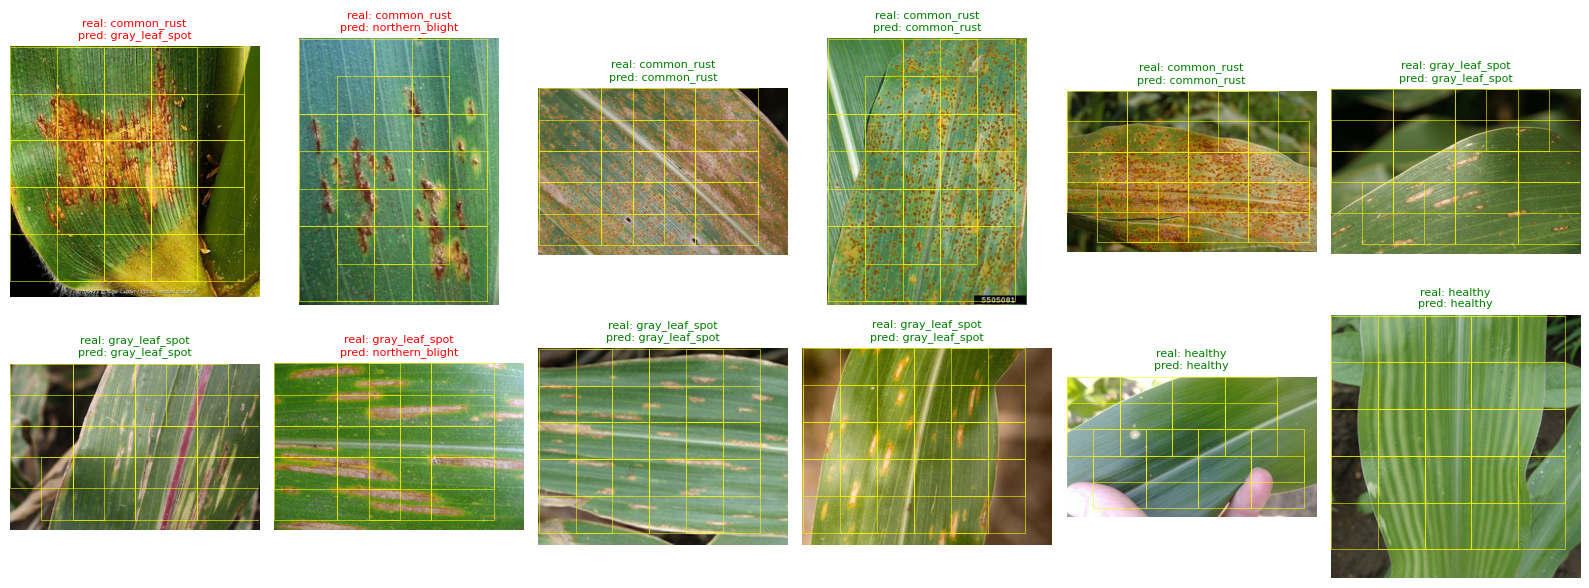

In [ ]:
import matplotlib.patches as mp

def ext_patches(path, k=16, stride=48):
    im = Image.open(path).convert("RGB")
    w, h = im.size; s = 256 / min(w, h)
    im = im.resize((max(PATCH, round(w * s)), max(PATCH, round(h * s))), Image.LANCZOS)
    W, H = im.size
    bx = [(y, x) for y in range(0, H - PATCH + 1, stride) for x in range(0, W - PATCH + 1, stride)]
    sel = np.unique(np.linspace(0, len(bx) - 1, k).round().astype(int))
    return im, [bx[j] for j in sel]

@torch.no_grad()
def predict_ext(path):
    im, bx = ext_patches(path)
    crops = [im.crop((x0, y0, x0 + PATCH, y0 + PATCH)) for y0, x0 in bx]
    out = {}
    for name, (net, size) in MODELS.items():
        tf = T.Compose([T.Resize(size), T.ToTensor(), T.Normalize(MEAN, STD)])
        x = torch.stack([tf(c) for c in crops]).to(DEVICE)
        out[name] = torch.softmax(net(x), 1).mean(0).cpu().numpy()
    return out, im, bx

rows, cache = [], {}
for cdir in sorted(EXT_DIR.iterdir()):
    if not cdir.is_dir():
        continue
    assert cdir.name in CLASSES, f"Carpeta '{cdir.name}' no es una clase válida: {CLASSES}"
    for f in sorted(cdir.glob("*.*")):
        probs, im, bx = predict_ext(f)
        cache[f.name] = (im, bx)
        row = dict(archivo=f.name, real=cdir.name)
        for name, p in probs.items():
            row[f"pred {name}"] = CLASSES[p.argmax()]; row[f"conf {name}"] = round(float(p.max()), 2)
        rows.append(row)
res = pd.DataFrame(rows)

print(f"Fotos: {len(res)}\n")
for name in MODELS:
    ok = res[f"pred {name}"] == res["real"]
    print(f"=== {name}: acierto {ok.mean():.3f} ({ok.sum()}/{len(res)})")
    print("recall por clase:", res.assign(ok=ok).groupby("real")["ok"].mean().round(2).to_dict())
    print(pd.crosstab(res["real"], res[f"pred {name}"]), "\n")

print("Errores:")
err = res[(res[[f"pred {n}" for n in MODELS]].ne(res["real"], axis=0)).any(axis=1)]
print(err.to_string(index=False))

# Revisión visual con EfficientNet
fig, axes = plt.subplots(2, 6, figsize=(16, 6))
for ax, r in zip(axes.ravel(), res.head(12).itertuples()):
    im, bx = cache[r.archivo]
    ax.imshow(im); ax.axis("off")
    for y0, x0 in bx:
        ax.add_patch(mp.Rectangle((x0, y0), PATCH, PATCH, fill=False, ec="yellow", lw=0.4))
    pred = getattr(r, "_" + str(list(res.columns).index("pred EfficientNet-B0") + 1))
    ax.set_title(f"real: {r.real}\npred: {pred}", fontsize=8, color="green" if pred == r.real else "red")
plt.tight_layout(); plt.show()

| Modelo | Aciertos |
|---|---|
| EfficientNet-B0 v1 | 15/20 (75%) |
| EfficientNet-B0 v2 | 15/20 (75%) |
| **EfficientNet-B0 v3** | **18/20 (90%)** |
| CNN segmented | 17/20 (85%) |
| CNN color | 16/20 (80%) |

**LIMITACIONES:**
- Son solo **20 fotos**: el intervalo de confianza es muy amplio (para 18/20 va de ~70% a ~97%), así que las diferencias entre modelos no son concluyentes.
- La confianza de las predicciones externas es baja en varias fotos (con frecuencia entre 0.4 y 0.7).

# **<font color= #7aa8a7> Grad-CAM: ¿en qué se fija el modelo? </font>**
Grad-CAM dibuja un mapa de calor sobre la foto con las zonas que más empujan la predicción. 

Se calcula por recorte y se promedia sobre la foto, y para cada modelo se muestran dos mapas con la **misma escala de color**: el de la clase que **predijo** y el de la clase **real**.

**Cómo leerlo:** si la zona caliente está sobre lesiones, el modelo se fija en lo correcto. Si está en el borde o el fondo, está usando una pista falsa.

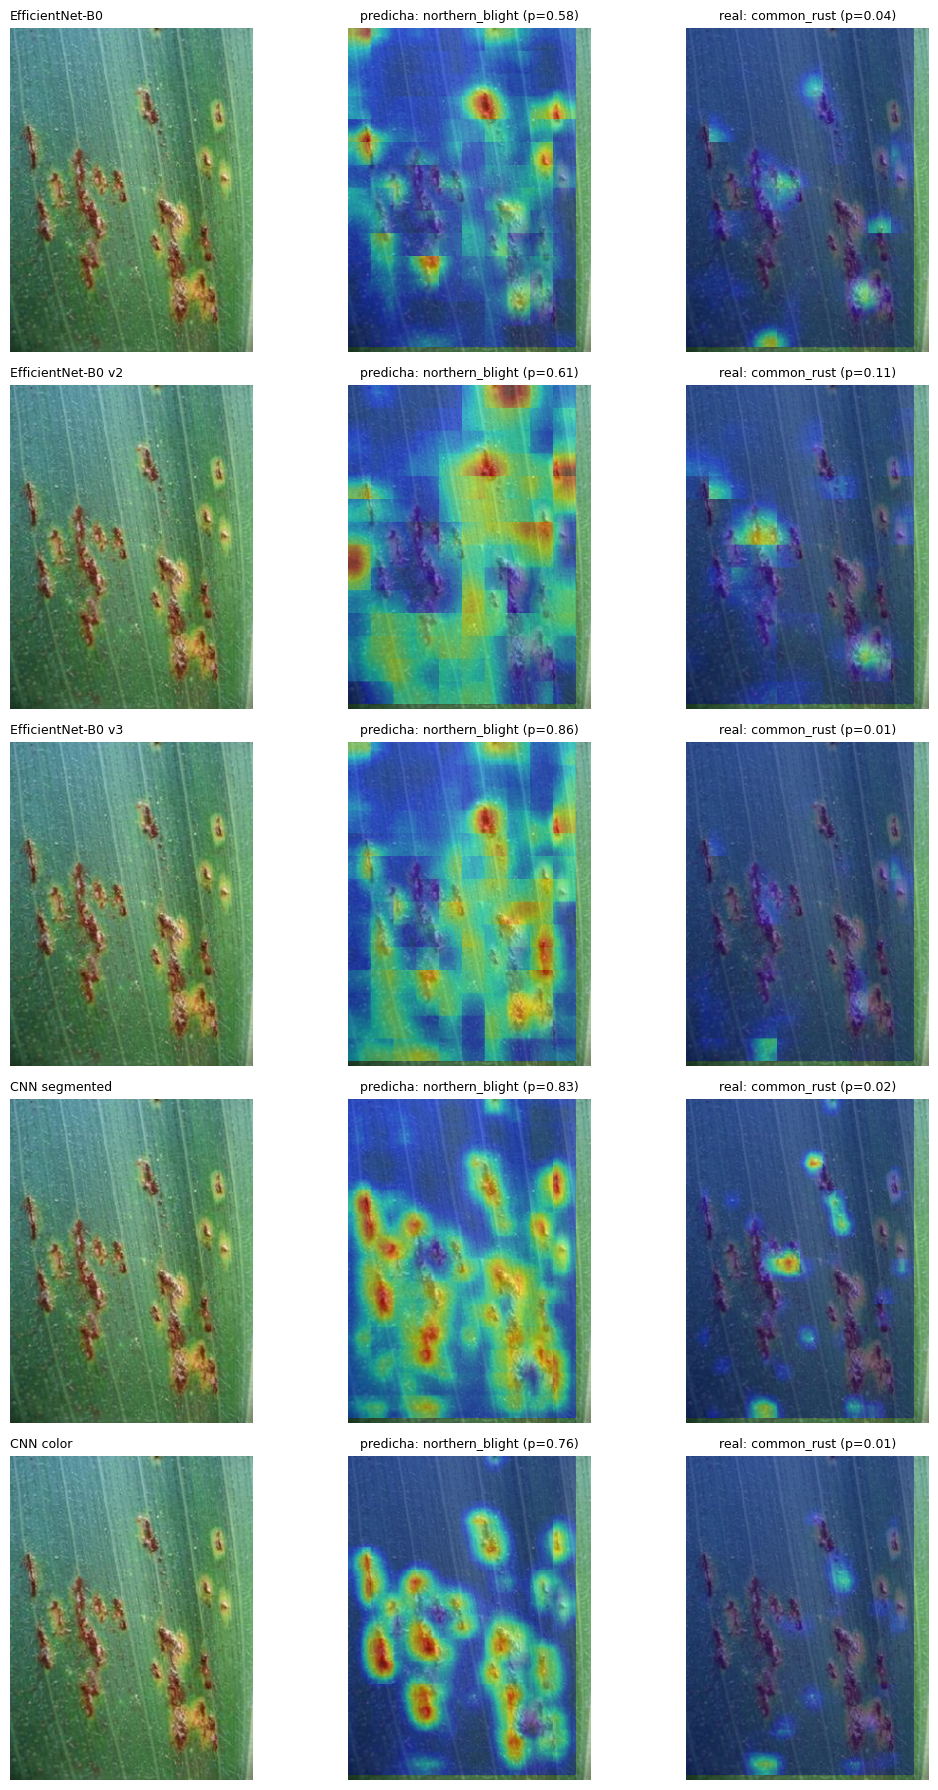

In [ ]:
for net, _ in MODELS.values():
    for m in net.modules():
        if hasattr(m, "inplace"):
            m.inplace = False

def target_layer(name):
    net, _ = MODELS[name]
    return net.features[-1] if "EfficientNet" in name else net.features[-1][5]   # última capa convolucional

def cam_patches(net, layer, x, cls):
    acts, grads = {}, {}
    def fwd(module, inp, out):
        acts["a"] = out
        out.register_hook(lambda g: grads.__setitem__("g", g))
    h = layer.register_forward_hook(fwd)
    net.zero_grad()
    with torch.enable_grad():
        logits = net(x)
        logits[:, cls].sum().backward()
    h.remove()
    w = grads["g"].mean(dim=(2, 3), keepdim=True)                 # importancia de cada canal
    cam = torch.relu((w * acts["a"]).sum(1, keepdim=True))        # (B, 1, h, w)
    cam = nn.functional.interpolate(cam, size=(PATCH, PATCH), mode="bilinear", align_corners=False)
    return cam[:, 0].detach().cpu().numpy()

def gradcam_photo(path, name, cls=None, k=64, stride=24):
    net, size = MODELS[name]
    im, bx = ext_patches(path, k=k, stride=stride)
    tf = T.Compose([T.Resize(size), T.ToTensor(), T.Normalize(MEAN, STD)])
    x = torch.stack([tf(im.crop((x0, y0, x0 + PATCH, y0 + PATCH))) for y0, x0 in bx]).to(DEVICE)
    x.requires_grad_(True)
    with torch.no_grad():
        probs = torch.softmax(net(x), 1).mean(0).cpu().numpy()      # probabilidad de la foto = promedio de recortes
    pred = int(probs.argmax())
    cams = cam_patches(net, target_layer(name), x, pred if cls is None else cls)
    W, H = im.size
    acc, cnt = np.zeros((H, W)), np.zeros((H, W))
    for (y0, x0), c in zip(bx, cams):
        acc[y0:y0 + PATCH, x0:x0 + PATCH] += c
        cnt[y0:y0 + PATCH, x0:x0 + PATCH] += 1
    heat = np.where(cnt > 0, acc / np.maximum(cnt, 1), np.nan)      # NaN = zona que ningún recorte cubrió
    return im, heat, pred, probs

def show_cam(real_cls, fname, names=None):
    path = EXT_DIR / real_cls / fname
    names = names or list(MODELS)
    fig, axes = plt.subplots(len(names), 3, figsize=(11, 3.6 * len(names)))
    axes = np.atleast_2d(axes)
    for r, name in enumerate(names):
        im, hp, pred, probs = gradcam_photo(path, name)
        _, ht, _, _ = gradcam_photo(path, name, cls=CLASS_TO_ID[real_cls])
        vmax = max(np.nanmax(hp), np.nanmax(ht), 1e-8)              # misma escala en los dos mapas
        axes[r, 0].imshow(im); axes[r, 0].set_title(name, fontsize=9, loc="left")
        for c, (h, cid) in enumerate([(hp, pred), (ht, CLASS_TO_ID[real_cls])], start=1):
            axes[r, c].imshow(im)
            axes[r, c].imshow(np.ma.masked_invalid(h), cmap="jet", alpha=0.45, vmin=0, vmax=vmax)
            axes[r, c].set_title(f"{'predicha' if c == 1 else 'real'}: {CLASSES[cid]} (p={probs[cid]:.2f})", fontsize=9)
        for a in axes[r]:
            a.axis("off")
    plt.tight_layout(); plt.show()

show_cam("common_rust", "rust2.jpg")

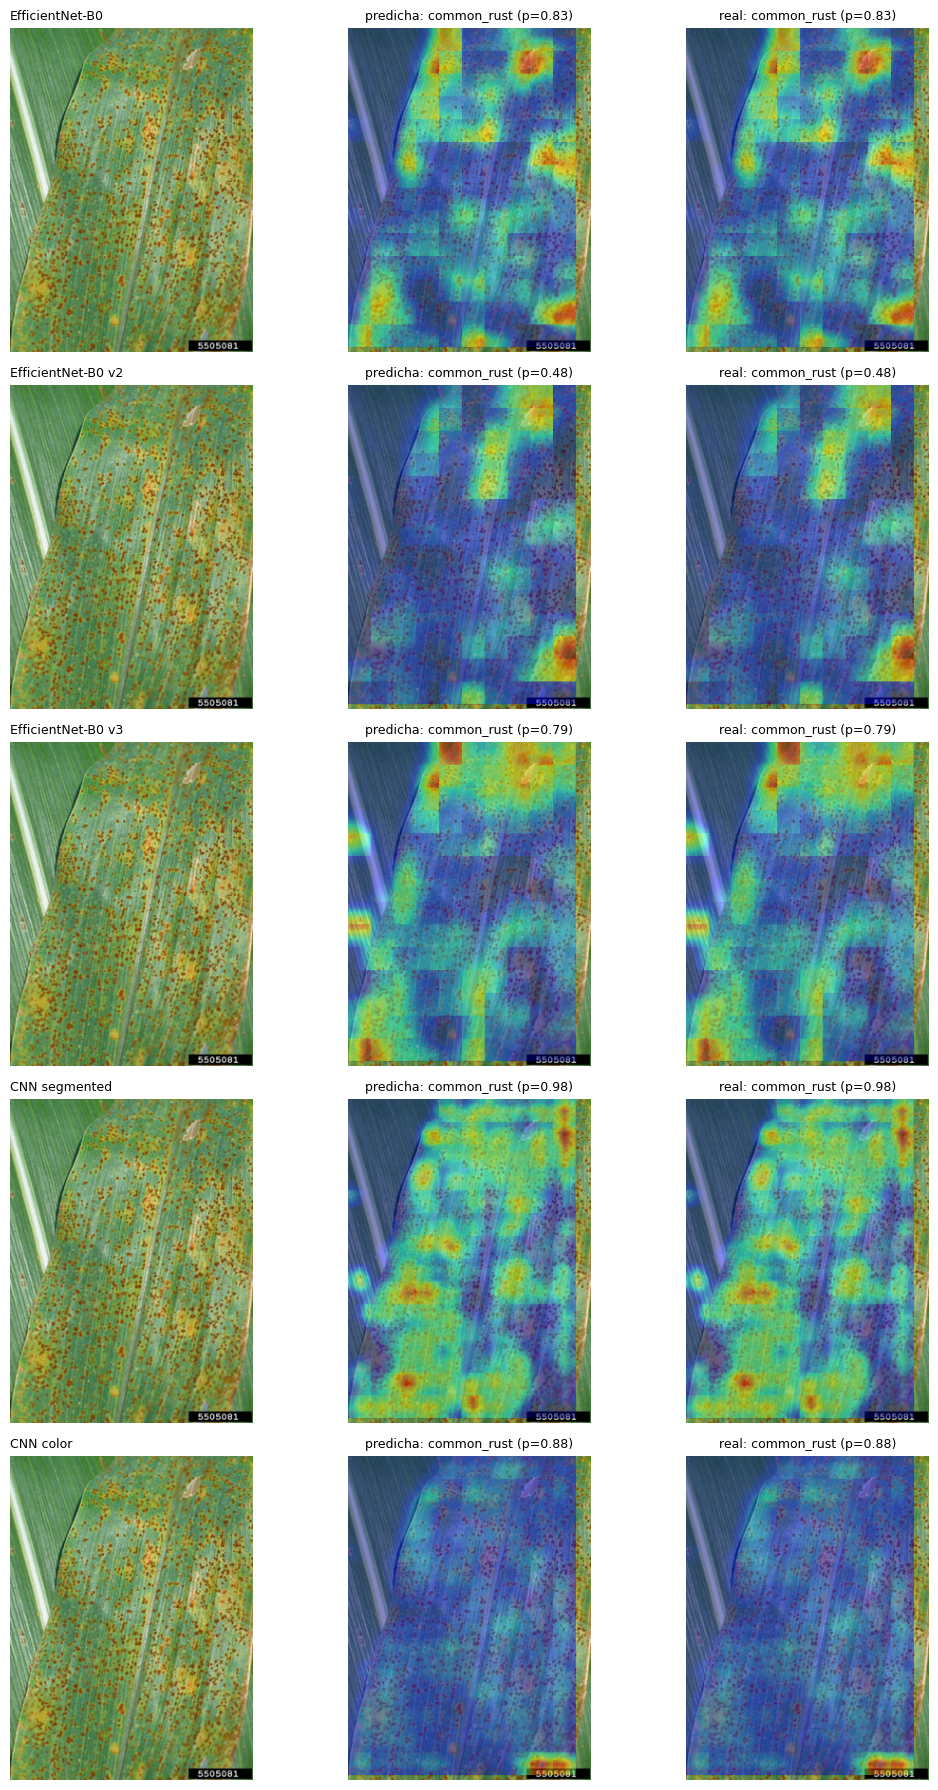

In [51]:
show_cam("common_rust", "rust4.jpg")